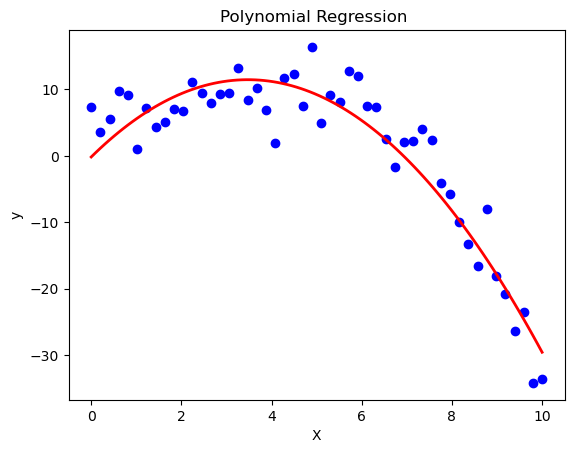

In [4]:
# Formula of Polynomial Regression:
# y = β₀ + β₁x + β₂x² + β₃x³ + ... + βₙxⁿ + ε

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

np.random.seed(0)
X = np.linspace(0, 10, 50).reshape(-1, 1)
y = (2 + 1.5*X + 0.5*X**2 - 0.1*X**3 + np.random.randn(50, 1)*3).ravel()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Polynomial Regression (degree = 3)
poly = PolynomialFeatures(degree=2)
X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

model = LinearRegression()
model.fit(X_poly_train, y_train)

# Predict curve
X_curve = np.linspace(0, 10, 100).reshape(-1, 1)
y_curve = model.predict(poly.transform(X_curve))

# Plot
plt.scatter(X, y, color='blue')
plt.plot(X_curve, y_curve, color='red', linewidth=2)
plt.title("Polynomial Regression ")
plt.xlabel("X")
plt.ylabel("y")
plt.show()



In [6]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Predictions on test set
y_pred_test = model.predict(X_poly_test)

# R² score
r2 = r2_score(y_test, y_pred_test)

# Mean Squared Error
mse = mean_squared_error(y_test, y_pred_test)

# Root Mean Squared Error
# rmse = mean_squared_error(y_test, y_pred_test, squared=False)

# Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred_test)

print(f"R² score: {r2:.4f}")
print(f"MSE: {mse:.4f}")
# print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")


R² score: 0.8304
MSE: 10.2149
MAE: 2.7743
